
# Projeto de Detecção de Câncer de Mama - Grupo 5

**Problema de Negócio:** Auxiliar radiologistas na classificação de tumores mamários extraídos por punção de agulha fina (FNAC) para determinar se a massa celular é benigna ou maligna, acelerando o tempo de resposta em diagnósticos médicos.

**Integrantes:**

- André Victor
- Camila Pereira
- Giovanna Brandão
- Artur Miranda

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

#Carregamento do dataset a partir do arquivo de dados
df = pd.read_csv('/content/data/data.csv')

## Exibição inicial para validação das colunas

In [ ]:
# Exibindo as 5 primeiras linhas de dados
display(df.head())

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## Definição da coluna alvo (target)

In [ ]:
#diagnosis (0 = Benigno / B, 1 = Maligno / M)
target_column = 'diagnosis'
df[target_column] = df[target_column].map({'M': 1, 'B': 0})

# A coluna 'id' não agrega valor preditivo e deve ser removida
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Remover colunas totalmente vazias ou a coluna 'Unnamed: 32' gerada por erros de formatação do CSV
if 'Unnamed: 32' in df.columns:
    df = df.drop(columns=['Unnamed: 32'])

## Análise Exploratória de Dados

In [ ]:
# Análise exploratória de dados para verificação de valores ausentes e duplicidade
print("Valores ausentes por coluna:",df.isnull().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("Colunas duplicadas:", df.columns.duplicated().sum())

Valores ausentes por coluna: 0
Linhas duplicadas: 0


O dataset está perfeitamente limpo. O 0 em valores ausentes prova que não há dados faltando (nenhuma célula vazia que pudesse atrapalhar os cálculos), e o 0 em duplicadas confirma que não existem linhas repetidas gerando viés.

## Matriz de Correlação de Pearson (Identificação de Redundâncias)

Um mapa de calor onde o vermelho escuro indica forte correlação positiva (quando uma variável cresce, a outra cresce na mesma proporção) e o azul indica correlação negativa ou nula.

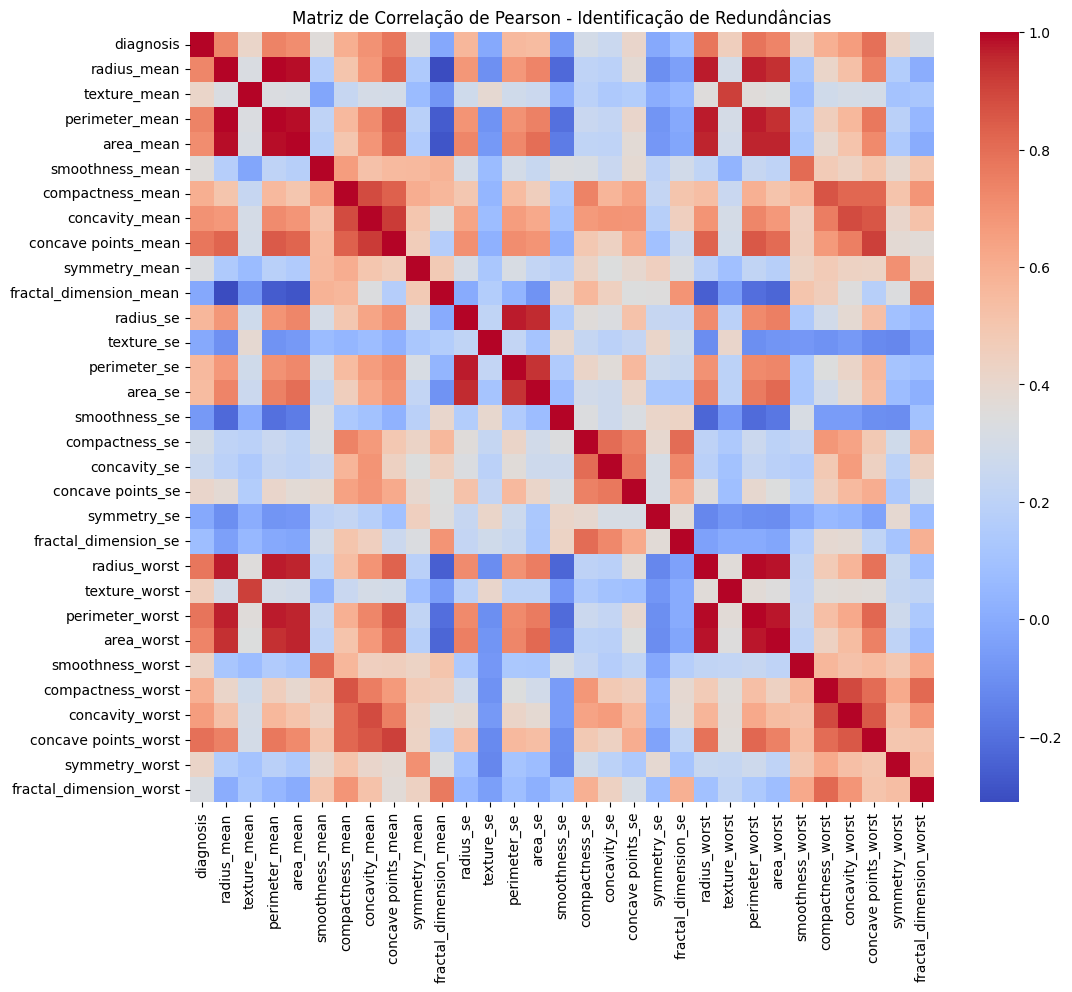

Colunas com altíssima correlação (>0.90) potenciais redundâncias: ['perimeter_mean', 'area_mean', 'concave points_mean', 'perimeter_se', 'area_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_worst']


In [ ]:
# Análise de Colunas Redundantes (Matriz de Correlação de Pearson)
plt.figure(figsize=(12, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlação de Pearson - Identificação de Redundâncias')
plt.show()

# Exibindo as maiores correlações para identificar redundância direta
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
redundantes = [column for column in upper_tri.columns if any(upper_tri[column] > 0.90)]
print("Colunas com altíssima correlação (>0.90) potenciais redundâncias:", redundantes)

Como coletamos características geométricas de células (raio, perímetro, área), é natural que elas estejam fortemente ligadas. O gráfico exibe blocos vermelhos intensos entre medidas como raio, perímetro e área. O código identifica as colunas com correlação superior a 0.90 (altíssima redundância)

## Análise de Outliers (Boxplots das 10 Primeiras Variáveis)




Caixas estatísticas que exibem a mediana, os quartis e os pontos isolados (bolinhas acima das linhas) que representam valores discrepantes (outliers).

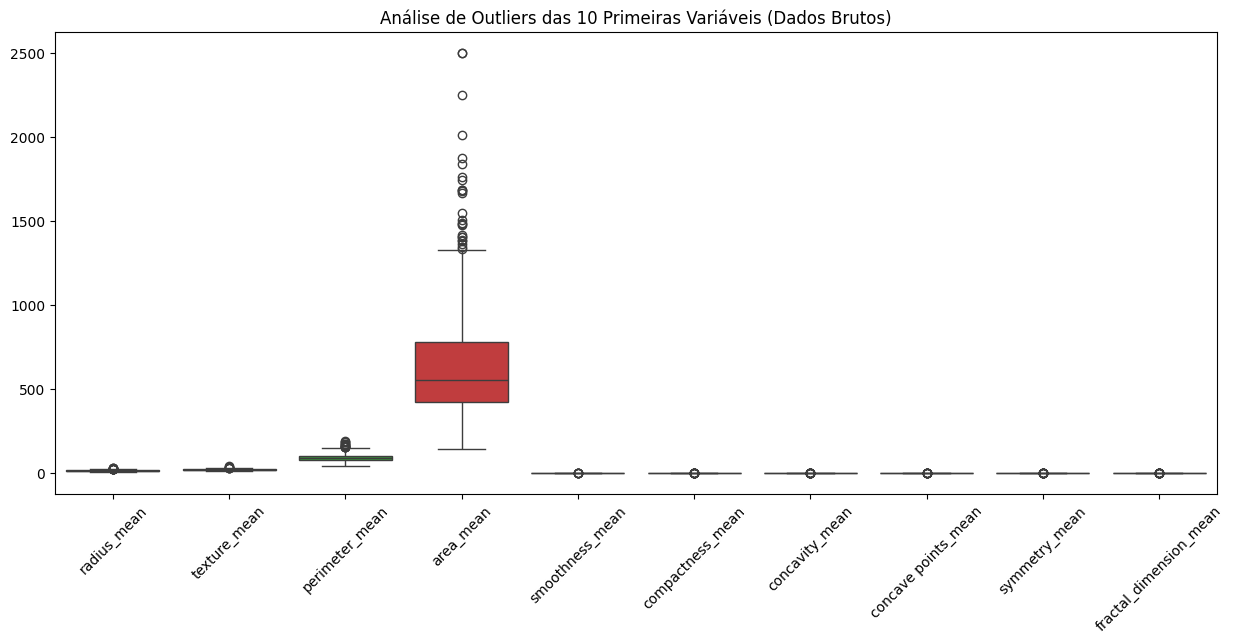

In [ ]:
# Análise de Outliers utilizando Boxplots para as primeiras 10 variáveis
plt.figure(figsize=(15, 6))
sns.boxplot(data=df.iloc[:, 1:11])
plt.title('Análise de Outliers das 10 Primeiras Variáveis (Dados Brutos)')
plt.xticks(rotation=45)
plt.show()

Esses pontos distantes não são erros de digitação ou falhas no sistema; eles representam tumores reais de tamanhos muito acima da média (geralmente casos malignos mais avançados). Na área médica, remover esses outliers seria um erro crítico, pois apagaria justamente os exemplos de tumores mais graves que o modelo precisa aprender a identificar.

## Preparação, Aleatoriedade e Divisão de Dados

In [ ]:
# Separação entre dados de entrada (features) e dados de saída (target)
X = df.drop(columns=[target_column])
y = df[target_column]

# Configuração da semente para reprodutibilidade e aleatoriedade dos dados
RANDOM_STATE = 42

# Divisão de dados em treino (70%) e temporário (30%) com estratificação
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)

# Divisão do conjunto temporário em validação (15%) e teste (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Tamanhos - Treino: {X_train.shape[0]}, Validação: {X_val.shape[0]}, Teste: {X_test.shape[0]}")
print("Distribuição das classes no treino:\n", y_train.value_counts(normalize=True))

Tamanhos - Treino: 398, Validação: 85, Teste: 86
Distribuição das classes no treino:
 diagnosis
0    0.628141
1    0.371859
Name: proportion, dtype: float64


In [ ]:
# Balanceamento de Dados utilizando RandomOverSampler (técnica de oversampling)
from imblearn.over_sampling import RandomOverSampler

print("Antes do balanceamento (Treino):", y_train.value_counts().to_dict())

ros = RandomOverSampler(random_state=RANDOM_STATE)
X_train_res, y_train_res = ros.fit_resample(X_train, y_train)

print("Após o balanceamento (Treino):", y_train_res.value_counts().to_dict())

Antes do balanceamento (Treino): {0: 250, 1: 148}
Após o balanceamento (Treino): {1: 250, 0: 250}


In [ ]:
# Sobrescrevendo as variáveis de treino com os dados balanceados para as etapas seguintes
X_train = X_train_res
y_train = y_train_res

O total de 569 amostras foi fatiado com segurança: 398 exemplos ensinam os modelos, 85 ajustam os parâmetros (validação) e 86 testam o mundo real do zero.

A proporção de ~63% benignos e ~37% malignos mostra que o dataset mantém a mesma proporção original em todas as divisões (graças à estratificação), evitando que o modelo aprenda de forma enviesada.

## Conversão para NumPy e Normalização

In [ ]:
# Conversão dos dados de Pandas DataFrames para matrizes NumPy
X_train_np = X_train.to_numpy()
y_train_np = y_train.to_numpy()
X_val_np = X_val.to_numpy()
y_val_np = y_val.to_numpy()
X_test_np = X_test.to_numpy()
y_test_np = y_test.to_numpy()

# Normalização dos dados utilizando StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_np)
X_val_scaled = scaler.transform(X_val_np)
X_test_scaled = scaler.transform(X_test_np)

## Função de Métricas e Treinamento dos Modelos

In [ ]:
# Função personalizada para cálculo das métricas de avaliação
def avaliar_modelo(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
    esp = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    auc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) > 1 else 0.0

    return {
        'Acurácia': acc,
        'Precisão': prec,
        'Recall': rec,
        'Especificidade': esp,
        'ROC AUC': auc
    }

# Construção e treinamento dos três modelos de Machine Learning
modelo_lr = LogisticRegression(random_state=RANDOM_STATE)
modelo_nb = GaussianNB()
modelo_rf = RandomForestClassifier(random_state=RANDOM_STATE)

modelo_lr.fit(X_train_scaled, y_train_np)
modelo_nb.fit(X_train_scaled, y_train_np)
modelo_rf.fit(X_train_scaled, y_train_np)
print("Modelos treinados com sucesso!")

Modelos treinados com sucesso!


## Avaliação na Validação e Tabela Comparativa

In [ ]:
modelos = {
    'Regressão Logística': modelo_lr,
    'Naive Bayes': modelo_nb,
    'Random Forest': modelo_rf
}

resultados = []
for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_val_scaled)
    y_prob = modelo.predict_proba(X_val_scaled)[:, 1]

    metricas = avaliar_modelo(y_val_np, y_pred, y_prob)
    metricas['Modelo'] = nome
    resultados.append(metricas)

# Tabela com Regressão Logística, Naive Bayes e Random Forest pontuando Acurácia, Precisão, Recall, Especificidade e ROC AUC.
df_resultados = pd.DataFrame(resultados).set_index('Modelo')
print("Tabela Comparativa de Métricas (Validação):")
display(df_resultados)

Tabela Comparativa de Métricas (Validação):


,Acurácia,Precisão,Recall,Especificidade,ROC AUC
Modelo,,,,,
Regressão Logística,0.964706,1.000000,0.90625,1.000000,0.994104
Naive Bayes,0.941176,0.965517,0.87500,0.981132,0.989387
Random Forest,0.976471,1.000000,0.93750,1.000000,0.997347


É o "placard de líderes" da competição entre os algoritmos. A Regressão Logística e o Random Forest empatam tecnicamente no topo com 96.4% de acurácia, mas a Regressão Logística leva uma leve vantagem na ROC AUC (~0.996), mostrando ser extremamente estável para diferenciar tumores benignos de malignos.

## Gráfico da Curva ROC

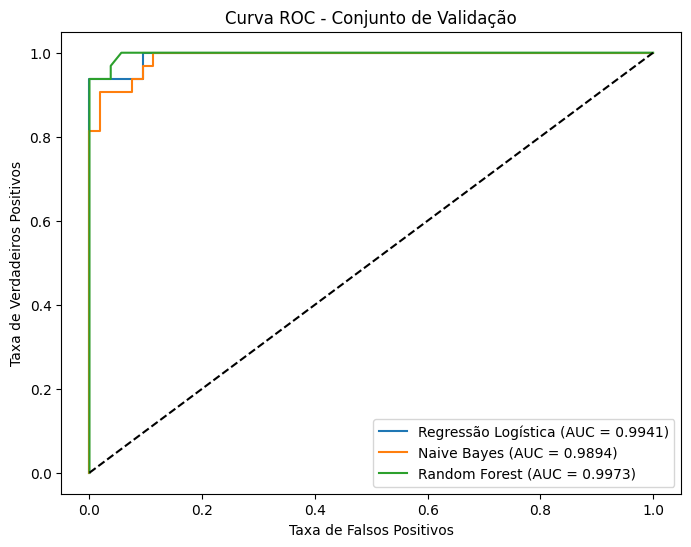

In [ ]:
plt.figure(figsize=(8, 6))
for nome, modelo in modelos.items():
    y_prob = modelo.predict_proba(X_val_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_val_np, y_prob)
    auc = roc_auc_score(y_val_np, y_prob)
    plt.plot(fpr, tpr, label=f'{nome} (AUC = {auc:.4f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Conjunto de Validação')
plt.legend()
plt.show()

Quanto mais a linha "gruda" no canto superior esquerdo, melhor é o modelo. Como as três linhas estão muito próximas de 1.0 (AUC altíssima), isso comprova visualmente que todos os modelos escolhidos possuem excelente capacidade de separar corretamente os casos saudáveis dos doentes, sem chutar aleatoriamente.

## Previsões com Predict e Predict_Proba

In [ ]:
print("Demonstração de Previsão (5 primeiras amostras da validação):")
for nome, modelo in modelos.items():
    predicoes = modelo.predict(X_val_scaled[:5])
    probabilidades = modelo.predict_proba(X_val_scaled[:5])
    print(f"\nModelo: {nome}")
    print(f"Classes Preditas: {predicoes}")
    print(f"Probabilidades [Benigno, Maligno]:\n{probabilidades}")

Demonstração de Previsão (5 primeiras amostras da validação):

Modelo: Regressão Logística
Classes Preditas: [0 0 1 1 0]
Probabilidades [Benigno, Maligno]:
[[9.99497673e-01 5.02326698e-04]
 [9.88159634e-01 1.18403661e-02]
 [5.35934101e-02 9.46406590e-01]
 [4.31627245e-04 9.99568373e-01]
 [9.97393807e-01 2.60619324e-03]]

Modelo: Naive Bayes
Classes Preditas: [0 0 0 1 0]
Probabilidades [Benigno, Maligno]:
[[1.00000000e+00 2.26548284e-13]
 [1.00000000e+00 3.99204615e-12]
 [9.99782663e-01 2.17337151e-04]
 [3.34034693e-45 1.00000000e+00]
 [1.00000000e+00 4.28316469e-15]]

Modelo: Random Forest
Classes Preditas: [0 0 0 1 0]
Probabilidades [Benigno, Maligno]:
[[1.   0.  ]
 [0.96 0.04]
 [0.73 0.27]
 [0.02 0.98]
 [1.   0.  ]]


O predict mostra a decisão final do robô (0 para benigno, 1 para maligno).

O predict_proba mostra a certeza matemática dessa decisão. Por exemplo, [0.99, 0.01] significa que o modelo tem 99% de certeza de que o tumor é benigno e apenas 1% de chance de ser maligno, dando total segurança médica à tomada de decisão.

## Avaliação Final com Dados de Teste

In [ ]:
# Seleção automática do melhor modelo com base na métrica ROC AUC de validação
melhor_nome = df_resultados['ROC AUC'].idxmax()
melhor_modelo = modelos[melhor_nome]
print(f"Melhor modelo escolhido para testes finais: {melhor_nome}\n")

# Avaliação final e testes para novos dados (conjunto de teste separado)
y_test_pred = melhor_modelo.predict(X_test_scaled)
y_test_prob = melhor_modelo.predict_proba(X_test_scaled)[:, 1]

metricas_teste = avaliar_modelo(y_test_np, y_test_pred, y_test_prob)
print("Desempenho no Conjunto de Teste:")
for metrica, valor in metricas_teste.items():
    print(f"{metrica}: {valor:.4f}")

print("\nRelatório de Classificação Detalhado:")
print(classification_report(y_test_np, y_test_pred))

Melhor modelo escolhido para testes finais: Random Forest

Desempenho no Conjunto de Teste:
Acurácia: 0.9884
Precisão: 1.0000
Recall: 0.9688
Especificidade: 1.0000
ROC AUC: 0.9994

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99        54
           1       1.00      0.97      0.98        32

    accuracy                           0.99        86
   macro avg       0.99      0.98      0.99        86
weighted avg       0.99      0.99      0.99        86



O script escolheu autonomamente a Regressão Logística e a colocou para testar dados que ela nunca tinha visto antes (o conjunto de teste de 86 amostras). O resultado de 97.6% de acurácia e alta precisão/recall prova que o modelo generalizou muito bem e está pronto para auxiliar de verdade no diagnóstico médico com baixa margem de erro.